# 06 — Phúc: báo cáo mở rộng ứng viên Teacher v1

Luồng: dữ liệu → mô hình → Group CV → xếp hạng ứng viên → fit Train → đọc lỗi → lưu báo cáo → minh họa ứng viên.

Theo yêu cầu mới: **chưa chốt Teacher**. 11 model E2 dùng 20 features và hai model TF-IDF dùng URL thô được trình bày để nhóm quyết định cả mô hình và hợp đồng inference. Không gán model đứng đầu thành Teacher chính thức. Kết quả MLP trước mở rộng có trong commit 19ceb7b; kết quả tuần 5 giữ nguyên.

Giữ Train IDs/3 domain folds, inner Group CV, AP chính, ngưỡng mặc định. Nhóm đã xem kết quả CV/Validation/external trước đây: đây là so sánh mở rộng trên cùng Train, không phải phép đánh giá xác nhận độc lập. Không dùng Validation/external/Test để chọn grid/model/ngưỡng. Official Test chưa chấm.


In [1]:
from pathlib import Path
from time import perf_counter
from io import BytesIO
from datetime import datetime, timezone
from importlib.metadata import version
import sys
import json
import hashlib
import subprocess
import warnings

import joblib
import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import average_precision_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.svm import LinearSVC
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import cross_val_predict
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
from phishguard_vn.brand_features import E2_FEATURES, BRAND_FEATURES, FEATURE_SCHEMA_VERSION, REFERENCE_PATH, load_reference
from phishguard_vn.features import CANDIDATE_FEATURES
from phishguard_vn.prediction import predict_url
from phishguard_vn.splits import audit_domain_overlap

DATA = ROOT / "data/interim"
OUT = ROOT / "reports/tables/week6"
FIGURES = ROOT / "reports/figures/week6"
for folder in [OUT, FIGURES, ROOT / "models"]:
    folder.mkdir(parents=True, exist_ok=True)
SEED = 42
PROTOCOL = "week6_e2_v1_teacher_groupcv_expanded"
FEATURES = list(E2_FEATURES)
CPU_LIMIT = threadpool_limits(limits=1)

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

print(ROOT, "|", FEATURE_SCHEMA_VERSION, "|", len(FEATURES), "features")

D:\PhishGuardVN | e2-brand-v1 | 20 features


## 1. Đọc dữ liệu và kiểm tra trước khi học

X là 20 đặc trưng E2 v1. y là nhãn; ID/domain/fold chỉ dùng để nối và kiểm tra. Hai URL lỗi vẫn ngoài X như tuần 4. Tập Test được lọc trước khi kiểm tra nhãn hay ghép X.

In [2]:
core = pd.read_csv(DATA / "core_gold_silver.csv", dtype={"id": "string"}, low_memory=False)
core = core.loc[core["split"].isin(["train", "val"])].copy()
X_table = pd.read_csv(DATA / "05_matrix_X_brand_trainval.csv", dtype={"id": "string"})
domains = pd.read_csv(DATA / "03_registrable_domains.csv", dtype={"id": "string"})
domains = domains.loc[domains["id"].isin(core["id"])].copy()
folds = pd.read_csv(DATA / "02_group_folds_train.csv", dtype={"id": "string"})
manifest = json.loads((DATA / "05_matrix_X_brand_trainval.manifest.json").read_text(encoding="utf-8"))
reference = load_reference()

assert FEATURE_SCHEMA_VERSION == manifest["feature_schema_version"] == "e2-brand-v1"
assert reference.is_fully_verified and manifest["brand_reference"]["sha256"] == reference.sha256
assert manifest["partition"] == "trainval" and manifest["test_excluded_from_this_artifact"]
assert manifest["columns"] == list(X_table.columns) == ["id", *FEATURES]
assert manifest["rows_x"] == len(X_table) and manifest["e1_columns_verified_identical_to_e1_matrix"]
assert manifest["input_sha256"] == sha256(DATA / "core_gold_silver.csv")
assert manifest["e1_feature_dictionary_sha256"] == sha256(ROOT / "reports/templates/feature_dictionary.csv")
assert manifest["brand_feature_dictionary_sha256"] == sha256(ROOT / "reports/templates/brand_feature_dictionary.csv")
for name, digest in manifest["splits_sha256"].items():
    assert name in ["url_train.csv", "url_val.csv"]
    assert sha256(ROOT / "data/splits" / name) == digest
for frame in [core, X_table, domains, folds]:
    assert frame["id"].notna().all() and frame["id"].str.strip().ne("").all()
    assert frame["id"].is_unique
assert core["tier"].isin(["gold", "silver"]).all()
assert core["label"].isin(["benign", "phishing"]).all()
assert set(core["id"]) == set(domains["id"])
assert np.isfinite(X_table[FEATURES].to_numpy(float)).all()

metadata = core[["id", "url", "label", "tier", "source", "split"]].merge(
    domains[["id", "registrable_domain"]], on="id", validate="one_to_one")
assert audit_domain_overlap(metadata)["status"] != "overlap_detected"
assert set(X_table["id"]) == set(metadata.loc[metadata["registrable_domain"].notna(), "id"])
e1 = pd.read_csv(DATA / "03_matrix_X_features.csv", dtype={"id": "string"}).set_index("id")
a = X_table.set_index("id")[list(CANDIDATE_FEATURES)].sort_index()
np.testing.assert_allclose(a, e1.loc[a.index, list(CANDIDATE_FEATURES)], rtol=0, atol=1e-9)
eligible = X_table.merge(metadata, on="id", validate="one_to_one")
assert list(folds.columns) == ["id", "fold_id"] and set(folds["fold_id"]) == {0, 1, 2}
assert set(folds["id"]) == set(eligible.loc[eligible["split"].eq("train"), "id"])
train = eligible.loc[eligible["split"].eq("train")].merge(
    folds, on="id", validate="one_to_one").sort_values("id").reset_index(drop=True)
validation = eligible.loc[eligible["split"].eq("val")].sort_values("id").reset_index(drop=True)
for frame in [train, validation]:
    frame["target"] = frame["label"].map({"benign": 0, "phishing": 1})
    assert frame["target"].nunique() == 2
assert train.groupby("registrable_domain")["fold_id"].nunique().eq(1).all()
assert set(train["registrable_domain"]).isdisjoint(validation["registrable_domain"])
print("Train:", len(train), "| Validation:", len(validation), "| Test không vào model")
display(train.groupby(["fold_id", "label"]).size().unstack(fill_value=0))

Train: 13078 | Validation: 1585 | Test không vào model


label,benign,phishing
fold_id,,
0,3668,691
1,3668,691
2,3668,692


## 2. Khai báo mô hình ngay tại đây

11 họ/cấu hình mốc E2: LR, LR balanced, RBF SVM, MLP, HistGB, RF, Extra Trees, Balanced RF, LightGBM, XGBoost và CatBoost. Mỗi họ tối đa hai cấu hình. Boosting không dùng eval_set/early stopping từ Validation hoặc outer holdout. Balanced RF resample bên trong mỗi fit; RF class_weight=balanced là đối chứng khác.

Hai đối chứng TF-IDF char 3–5 + Linear SVM/LR dùng đúng Train IDs và folds nhưng nhận chuỗi URL gốc thay vì 20 số E2. Giữ chữ hoa/thường, tối đa 50.000 n-gram, min_df=2; vocabulary/IDF chỉ fit trong Pipeline. Đây là kiểm tra giới hạn biểu diễn, không phải Teacher E2 drop-in. URL gốc khác cách ghi scheme/path giữa nguồn có thể tạo source bias.

Cài dependencies train bằng: pip install -e ".[teacher,test]"


In [3]:
# Các model E2 dùng cùng 20 cột; mọi grid được cố định trước lần chạy mở rộng.
lr = Pipeline([("scaler", StandardScaler()),
               ("model", LogisticRegression(C=1.0, max_iter=2000, random_state=SEED))])
lr_balanced = Pipeline([("scaler", StandardScaler()),
                        ("model", LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEED))])
svm = Pipeline([("scaler", StandardScaler()), ("model", SVC(kernel="rbf", gamma="scale", cache_size=256))])
mlp = Pipeline([("scaler", StandardScaler()),
                ("model", MLPClassifier(alpha=0.001, max_iter=1000, batch_size=256,
                                        early_stopping=False, n_iter_no_change=20, random_state=SEED))])
histgb = HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1,
                                        l2_regularization=1.0, early_stopping=False, random_state=SEED)
forest = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, max_features="sqrt",
                                class_weight="balanced", n_jobs=1, random_state=SEED)
extra = ExtraTreesClassifier(n_estimators=200, min_samples_leaf=2, max_features="sqrt",
                             class_weight="balanced", n_jobs=1, random_state=SEED)
balanced_forest = BalancedRandomForestClassifier(n_estimators=200, min_samples_leaf=2,
    sampling_strategy="all", replacement=True, bootstrap=False, n_jobs=1, random_state=SEED)
lightgbm = LGBMClassifier(n_estimators=200, learning_rate=0.05, min_child_samples=20,
    reg_lambda=1.0, deterministic=True, force_col_wise=True, verbosity=-1, n_jobs=1, random_state=SEED)
xgboost = XGBClassifier(n_estimators=200, learning_rate=0.05, tree_method="hist",
    objective="binary:logistic", eval_metric="logloss", reg_lambda=1.0, n_jobs=1, random_state=SEED)
catboost = CatBoostClassifier(iterations=200, learning_rate=0.05, loss_function="Logloss",
    l2_leaf_reg=3.0, thread_count=1, random_seed=SEED, verbose=False,
    allow_writing_files=False, use_best_model=False)

# TF-IDF là đối chứng URL thô, không đổi hợp đồng Teacher E2 v1.
# Vocabulary/IDF phải được fit bên trong Pipeline của từng fitting fold.
text_svm = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(3, 5), min_df=2,
                              max_features=50000, sublinear_tf=True, lowercase=False)),
    ("model", LinearSVC(max_iter=10000, random_state=SEED))])
text_lr = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="char", ngram_range=(3, 5), min_df=2,
                              max_features=50000, sublinear_tf=True, lowercase=False)),
    ("model", LogisticRegression(solver="liblinear", max_iter=2000, random_state=SEED))])
RAW_MODEL_NAMES = {"tfidf_linear_svm", "tfidf_logistic_regression"}
models = {"logistic_regression": lr, "logistic_regression_balanced": lr_balanced,
          "svm_rbf": svm, "mlp": mlp, "hist_gradient_boosting": histgb, "random_forest": forest,
          "extra_trees": extra, "balanced_random_forest": balanced_forest,
          "lightgbm": lightgbm, "xgboost": xgboost, "catboost": catboost,
          "tfidf_linear_svm": text_svm, "tfidf_logistic_regression": text_lr}
param_grids = {"logistic_regression": {}, "logistic_regression_balanced": {},
               "svm_rbf": {"model__C": [0.5, 2.0]},
               "mlp": {"model__hidden_layer_sizes": [(32,), (32, 16)]},
               "hist_gradient_boosting": {"max_leaf_nodes": [7, 15]},
               "random_forest": {"max_depth": [12, None]},
               "extra_trees": {"max_depth": [12, None]},
               "balanced_random_forest": {"max_depth": [12, None]},
               "lightgbm": {"num_leaves": [7, 15]},
               "xgboost": {"max_depth": [3, 5]},
               "catboost": {"depth": [4, 6]},
               "tfidf_linear_svm": {"model__C": [0.5, 2.0]},
               "tfidf_logistic_regression": {"model__C": [0.5, 2.0]}}
assert set(models) == set(param_grids)


## 3. Các hàm ngắn dùng trong các bước dưới

inner_splits kiểm tra group; model_input chọn 20 số hoặc chuỗi URL; ranking_scores lấy xác suất/margin; calculate_metrics tính bảng điểm. threshold_at_train_fpr chỉ nhận inner-OOF của fitting để tìm ngưỡng phụ FPR ≤ 2% trên phần calibration.

AP dùng score liên tục; nhãn chính lấy predict mặc định. Ngưỡng phụ không đổi Teacher hoặc script inference.


In [4]:
def inner_splits(fitting):
    splitter = StratifiedGroupKFold(n_splits=2, shuffle=True, random_state=SEED)
    splits = list(splitter.split(fitting[FEATURES], fitting["target"], fitting["registrable_domain"]))
    for a, b in splits:
        assert set(fitting.iloc[a]["registrable_domain"]).isdisjoint(fitting.iloc[b]["registrable_domain"])
        assert fitting.iloc[a]["target"].nunique() == fitting.iloc[b]["target"].nunique() == 2
    return splits

def model_input(name, frame):
    # E2 -> 20 số; TF-IDF -> chuỗi URL. Không truyền ID/nhãn/nguồn vào model.
    return frame["url"].astype(str) if name in RAW_MODEL_NAMES else frame[FEATURES]

def ranking_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, list(model.classes_).index(1)]
    return model.decision_function(X)

def calculate_metrics(y, predicted, score):
    tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
    return {"pr_auc": average_precision_score(y, score),
            "precision_phishing": precision_score(y, predicted, zero_division=0),
            "recall_phishing": recall_score(y, predicted, zero_division=0),
            "f1_phishing": f1_score(y, predicted, zero_division=0),
            "false_positive_rate": fp / (fp + tn),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}

def threshold_at_train_fpr(y, scores, limit=0.02):
    # Chỉ nhận inner-OOF scores của fitting. Vượt qua các ties để FPR không vượt giới hạn.
    negatives = np.asarray(scores)[np.asarray(y) == 0]
    assert len(negatives) and np.isfinite(negatives).all() and 0 < limit < 1
    boundary = np.quantile(negatives, 1 - limit, method="higher")
    return float(np.nextafter(boundary, np.inf))


## 4. Chạy ba outer folds — tạo dự đoán OOF

Giữ một fold ngoài; chọn cấu hình bằng hai inner group folds trong fitting; predict fold giữ ngoài. Mỗi URL Train có đúng một OOF prediction/model.

Phân tích phụ FPR thấp: clone cấu hình đã chọn, tạo inner-OOF scores chỉ trong fitting rồi lấy quantile của benign để chọn ngưỡng. Sau đó áp dụng nguyên ngưỡng đó vào outer holdout. Không chọn ngưỡng trên outer OOF đã gộp. FPR outer thực tế có thể vượt 2%; phải báo số thực tế, không gọi đây là cam kết FPR 2%.


In [5]:
cv_rows, low_fpr_rows, prediction_tables, parameter_rows, partition_tables = [], [], [], [], []
for fold_id in [0, 1, 2]:
    fitting = train.loc[train["fold_id"].ne(fold_id)]
    held_out = train.loc[train["fold_id"].eq(fold_id)]
    assert set(fitting["id"]).isdisjoint(held_out["id"])
    assert set(fitting["registrable_domain"]).isdisjoint(held_out["registrable_domain"])
    splits = inner_splits(fitting)
    assignments = pd.DataFrame({"id": fitting["id"].to_numpy(), "context": str(fold_id),
                                "role": "fitting", "inner_fold_id": -1})
    for i, (_, score_index) in enumerate(splits):
        assignments.loc[score_index, "inner_fold_id"] = i
    partition_tables.extend([assignments, pd.DataFrame({"id": held_out["id"].to_numpy(),
                              "context": str(fold_id), "role": "held_out", "inner_fold_id": -1})])
    for name, model in models.items():
        print("Fitting", name, "fold", fold_id, flush=True)
        start = perf_counter()
        X_fit, X_holdout = model_input(name, fitting), model_input(name, held_out)
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            if param_grids[name]:
                search = GridSearchCV(clone(model), param_grids[name], scoring="average_precision",
                                      cv=splits, n_jobs=1, error_score="raise", refit=True)
                search.fit(X_fit, fitting["target"])
                fitted, best_params = search.best_estimator_, search.best_params_
            else:
                fitted = clone(model).fit(X_fit, fitting["target"])
                best_params = {}
            method = "predict_proba" if hasattr(fitted, "predict_proba") else "decision_function"
            inner_scores = cross_val_predict(clone(fitted), X_fit, fitting["target"],
                                             cv=splits, method=method, n_jobs=1)
        if method == "predict_proba":
            inner_scores = inner_scores[:, list(fitted.classes_).index(1)]
        threshold = threshold_at_train_fpr(fitting["target"], inner_scores)
        calibration = calculate_metrics(fitting["target"], inner_scores >= threshold, inner_scores)
        assert calibration["false_positive_rate"] <= 0.02

        predicted = np.asarray(fitted.predict(X_holdout)).ravel()
        score = ranking_scores(fitted, X_holdout)
        predicted_low_fpr = (score >= threshold).astype(int)
        assert list(fitted.classes_) == [0, 1] and np.isfinite(score).all()
        feature_set = "url_char_tfidf" if name in RAW_MODEL_NAMES else FEATURE_SCHEMA_VERSION
        cv_rows.append({"model": name, "feature_set": feature_set, "fold_id": fold_id,
                        "fit_seconds": perf_counter() - start,
                        **calculate_metrics(held_out["target"], predicted, score)})
        low_fpr_rows.append({"model": name, "feature_set": feature_set, "fold_id": fold_id,
            "threshold_from_inner_oof": threshold, "calibration_rows": len(fitting),
            "calibration_negatives": int(fitting["target"].eq(0).sum()),
            "calibration_fp": calibration["fp"],
            "calibration_fpr": calibration["false_positive_rate"],
            **calculate_metrics(held_out["target"], predicted_low_fpr, score)})
        prediction_tables.append(pd.DataFrame({"id": held_out["id"].to_numpy(), "model": name,
                "fold_id": fold_id, "true_label": held_out["target"].to_numpy(),
                "predicted_label": predicted, "score": score, "score_kind": "probability" if method == "predict_proba" else "decision_function",
                "threshold_from_inner_oof": threshold, "predicted_label_train_fpr2pct": predicted_low_fpr}))
        parameter_rows.append({"model": name, "context": str(fold_id),
                               "parameters": json.dumps(best_params, sort_keys=True)})
        print(name, "fold", fold_id, "AP =", round(cv_rows[-1]["pr_auc"], 4), flush=True)
cv_metrics, low_fpr_metrics = pd.DataFrame(cv_rows), pd.DataFrame(low_fpr_rows)
oof = pd.concat(prediction_tables, ignore_index=True)
partitions = pd.concat(partition_tables, ignore_index=True)
assert not oof.duplicated(["model", "id"]).any()
assert oof.groupby("model").size().eq(len(train)).all()
assert set(oof["id"]) == set(train["id"])


Fitting logistic_regression fold 0


logistic_regression fold 0 AP = 0.6442


Fitting logistic_regression_balanced fold 0


logistic_regression_balanced

 fold 0 AP = 0.6274


Fitting svm_rbf fold 0


... (69 outputs left out)

Fitting tfidf_linear_svm fold 2


tfidf_linear_svm fold 2 AP = 0.916


Fitting tfidf_logistic_regression fold 2


tfidf_logistic_regression fold 2 AP = 0.9155


## 5. Xếp hạng và báo cáo — chưa chốt Teacher

Mean AP giảm dần, hòa thì F1 cao hơn, FPR thấp hơn rồi tên. Ghi riêng ứng viên đứng đầu E2 và URL thô; hai nhóm có đầu vào khác nhau. Nhóm sẽ quyết định giữ contract 20 số hay đổi sang URL thô, sau đó mới chốt Teacher.

Các outer folds đã được dùng nhiều lần để so sánh model. Mean/std mô tả kết quả, không phải ước lượng độc lập sau lựa chọn hay khoảng tin cậy.


In [6]:
metric_names = ["pr_auc", "recall_phishing", "false_positive_rate", "f1_phishing", "precision_phishing"]
comparison = cv_metrics.groupby("model")[metric_names].agg(["mean", "std"])
comparison.columns = [f"{m}_{s}" for m, s in comparison.columns]
comparison = comparison.reset_index().sort_values(
    ["pr_auc_mean", "f1_phishing_mean", "false_positive_rate_mean", "model"],
    ascending=[False, False, True, True]).reset_index(drop=True)
comparison["feature_set"] = np.where(comparison["model"].isin(RAW_MODEL_NAMES),
                                      "url_char_tfidf", FEATURE_SCHEMA_VERSION)
comparison["e2_contract_compatible"] = comparison["feature_set"].eq(FEATURE_SCHEMA_VERSION)
candidate_name = str(comparison.loc[comparison["e2_contract_compatible"]].iloc[0]["model"])
raw_ranking = comparison.loc[~comparison["e2_contract_compatible"]]
raw_candidate_name = str(raw_ranking.iloc[0]["model"]) if len(raw_ranking) else None
teacher_finalized = False
print("Chưa chốt Teacher; dẫn đầu E2:", candidate_name, "| URL thô:", raw_candidate_name)
display(comparison)
print("Ngưỡng FPR 2% là phân tích phụ; FPR outer thực tế có thể khác 2%.")
display(low_fpr_metrics.groupby("model")[["recall_phishing", "false_positive_rate", "f1_phishing"]].mean())


Chưa chốt Teacher; dẫn đầu E2: catboost | URL thô: tfidf_linear_svm


,model,pr_auc_mean,pr_auc_std,recall_phishing_mean,recall_phishing_std,false_positive_rate_mean,false_positive_rate_std,f1_phishing_mean,f1_phishing_std,precision_phishing_mean,precision_phishing_std,feature_set,e2_contract_compatible
0,tfidf_linear_svm,0.925628,0.013656,0.777730,0.012976,0.011360,0.001399,0.846254,0.010988,0.928056,0.009051,url_char_tfidf,False
1,tfidf_logistic_regression,0.922154,0.010889,0.708302,0.016021,0.007724,0.001550,0.809770,0.013392,0.945287,0.010979,url_char_tfidf,False
2,catboost,0.733188,0.003742,0.498093,0.040783,0.015722,0.003897,0.629181,0.027432,0.858050,0.021481,e2-brand-v1,True
3,mlp,0.726370,0.017394,0.500968,0.010135,0.018811,0.002885,0.625909,0.010894,0.834180,0.021517,e2-brand-v1,True
4,hist_gradient_boosting,0.723026,0.016832,0.506768,0.035250,0.019993,0.001502,0.627932,0.027031,0.826944,0.001709,e2-brand-v1,True
5,lightgbm,0.722158,0.021838,0.496647,0.041731,0.018448,0.002204,0.622247,0.033017,0.835535,0.010413,e2-brand-v1,True
6,balanced_random_forest,0.719169,0.008673,0.732397,0.015149,0.164486,0.023619,0.562978,0.021120,0.458048,0.031237,e2-brand-v1,True
7,xgboost,0.718343,0.018011,0.462900,0.049703,0.013904,0.002846,0.601413,0.042394,0.862941,0.018031,e2-brand-v1,True
8,random_forest,0.717593,0.006483,0.730941,0.029217,0.170665,0.033072,0.555673,0.024138,0.450131,0.042392,e2-brand-v1,True
9,extra_trees,0.706487,0.023948,0.817709,0.061848,0.255180,0.047962,0.516437,0.011861,0.378936,0.024516,e2-brand-v1,True


Ngưỡng FPR 2% là phân tích phụ; FPR outer thực tế có thể khác 2%.


,recall_phishing,false_positive_rate,f1_phishing
model,,,
balanced_random_forest,0.500002,0.019629,0.622800
catboost,0.531823,0.020538,0.648070
extra_trees,0.455630,0.016721,0.589041
hist_gradient_boosting,0.503875,0.019538,0.626368
lightgbm,0.487964,0.016449,0.619021
logistic_regression,0.355843,0.019811,0.486954
logistic_regression_balanced,0.319182,0.019629,0.447596
mlp,0.475895,0.015540,0.610836
random_forest,0.509172,0.019629,0.631001


## 6. Fit ứng viên trên toàn Train, xem Validation bổ sung

Mỗi model cuối chỉ học Train; tham số chọn bằng inner Group CV trên Train. Validation dùng báo cáo giới hạn phân bố, không đổi grid hoặc thứ hạng Core CV. Model không hội tụ sẽ dừng. Chưa chọn bất kỳ model fit toàn Train nào làm Teacher chính thức.


In [7]:
final_models, validation_rows, validation_tables = {}, [], []
splits = inner_splits(train)
assignments = pd.DataFrame({"id": train["id"].to_numpy(), "context": "full_train",
                           "role": "fitting", "inner_fold_id": -1})
for i, (_, score_index) in enumerate(splits):
    assignments.loc[score_index, "inner_fold_id"] = i
partitions = pd.concat([partitions, assignments], ignore_index=True)
for name, model in models.items():
    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)
        if param_grids[name]:
            search = GridSearchCV(clone(model), param_grids[name], scoring="average_precision",
                                  cv=splits, n_jobs=1, error_score="raise", refit=True)
            search.fit(model_input(name, train), train["target"])
            fitted, best_params = search.best_estimator_, search.best_params_
        else:
            fitted = clone(model).fit(model_input(name, train), train["target"])
            best_params = {}
    final_models[name] = fitted
    parameter_rows.append({"model": name, "context": "full_train",
                           "parameters": json.dumps(best_params, sort_keys=True)})
    predicted = np.asarray(fitted.predict(model_input(name, validation))).ravel()
    score = ranking_scores(fitted, model_input(name, validation))
    validation_rows.append({"model": name, **calculate_metrics(validation["target"], predicted, score)})
    validation_tables.append(pd.DataFrame({"id": validation["id"].to_numpy(), "model": name,
        "true_label": validation["target"].to_numpy(), "predicted_label": predicted, "score": score}))
validation_metrics = pd.DataFrame(validation_rows)
validation_predictions = pd.concat(validation_tables, ignore_index=True)
display(validation_metrics)

,model,pr_auc,precision_phishing,recall_phishing,f1_phishing,false_positive_rate,tn,fp,fn,tp
0,logistic_regression,0.348878,0.288889,0.541667,0.376812,0.020500,1529,32,11,13
1,logistic_regression_balanced,0.310228,0.054502,0.958333,0.103139,0.255605,1162,399,1,23
2,svm_rbf,0.244777,0.352941,0.500000,0.413793,0.014094,1539,22,12,12
3,mlp,0.393050,0.250000,0.500000,0.333333,0.023062,1525,36,12,12
4,hist_gradient_boosting,0.447271,0.378378,0.583333,0.459016,0.014734,1538,23,10,14
5,random_forest,0.385363,0.050218,0.958333,0.095436,0.278668,1126,435,1,23
6,extra_trees,0.277549,0.034884,1.000000,0.067416,0.425368,897,664,0,24
7,balanced_random_forest,0.379692,0.061995,0.958333,0.116456,0.222934,1213,348,1,23
8,lightgbm,0.455605,0.370370,0.416667,0.392157,0.010890,1544,17,14,10
9,xgboost,0.477968,0.346154,0.375000,0.360000,0.010890,1544,17,15,9


## 7. Đọc ít nhất 10 lỗi OOF của ứng viên E2 dẫn đầu

Mẫu hai FP và hai FN ở mỗi fold, chọn theo ID cố định. Đây là phân tích ứng viên E2, không ngụ ý đã chọn Teacher. Quan sát/giả thuyết/bước kiểm tra được tách rõ; không phải xác minh nhãn hoặc chứng minh nguyên nhân.


In [8]:
candidate_oof = oof.loc[oof["model"].eq(candidate_name)].merge(
    train[["id", "url", "source", "registrable_domain", *FEATURES]], on="id", validate="one_to_one")
mistakes = candidate_oof.loc[candidate_oof["true_label"].ne(candidate_oof["predicted_label"])].copy()
mistakes["error"] = np.where(mistakes["true_label"].eq(0), "FP", "FN")
error_examples = mistakes.sort_values("id").groupby(["fold_id", "error"], sort=True).head(2).copy()
assert len(error_examples) >= 10 and error_examples["id"].is_unique
error_notes = []
for row in error_examples.itertuples():
    fitting = train.loc[train["fold_id"].ne(row.fold_id)]
    values = np.array([getattr(row, c) for c in FEATURES], dtype=float)
    same_vector = np.isclose(fitting[FEATURES].to_numpy(float), values, rtol=0, atol=1e-12).all(axis=1)
    opposite = int((same_vector & fitting["target"].ne(row.true_label).to_numpy()).sum())
    active = [c for c in BRAND_FEATURES if getattr(row, c) != 0]
    observation = (f"{row.error}, fold {row.fold_id}, score={row.score:.4f}; "
                   f"url_len={row.url_len:g}, dom_len={row.dom_len:g}, entropy={row.entropy:.3f}; "
                   f"brand khác 0: {', '.join(active) or 'không có'}; "
                   f"{opposite} mẫu nhãn đối lập cùng vector E2 trong fitting fold.")
    if opposite:
        hypothesis = "Biểu diễn E2 có thể chưa tách được các URL khác nhãn nhưng có cùng vector."
        next_check = f"Đối chiếu {opposite} fitting rows trùng vector với ID {row.id}; xem nhãn/nguồn, không sửa nhãn theo dự đoán."
    elif row.error == "FP" and row.brand_domain_mismatch:
        hypothesis = "Brand mismatch có thể là false match hoặc reference chưa bao phủ; chưa chứng minh đây là nguyên nhân dự đoán."
        next_check = f"Dùng explain_brand_matches cho hostname {row.registrable_domain}; đối chiếu alias/domain trong reference v1."
    elif row.error == "FN" and not active:
        hypothesis = "Không có tín hiệu brand ở mẫu này; các đặc trưng cấu trúc có thể giống benign trong fitting."
        next_check = f"So URL {row.id} với fitting cùng độ dài/domain length; kiểm tra giới hạn reference mà không chọn rule theo holdout."
    else:
        hypothesis = "Tín hiệu cấu trúc/brand có thể chồng lấn giữa hai lớp; score không phải bằng chứng nhãn nguồn sai."
        next_check = f"Đối chiếu feature của {row.id} trong chính fitting fold và kiểm tra matching; không tune theo lỗi holdout này."
    error_notes.append({"observation": observation, "hypothesis": hypothesis, "next_check": next_check,
                        "opposite_label_same_vector_in_fitting": opposite,
                        "analysis_method": "offline_feature_evidence_not_human_label_verification"})
error_examples = pd.concat([error_examples.reset_index(drop=True), pd.DataFrame(error_notes)], axis=1)
error_examples["url"] = error_examples["url"].str.replace(".", "[.]", regex=False)
display(error_examples[["id", "fold_id", "error", "url", "score", "observation", "hypothesis", "next_check"]])

,id,fold_id,error,url,score,observation,hypothesis,next_check
0,0017a2da-35d5-588f-8062-349ea6be2ec7,0,FN,kokatrade[.]com,0.133865,"FN, fold 0, score=0.1339; url_len=13, dom_len=...",Biểu diễn E2 có thể chưa tách được các URL khá...,Đối chiếu 67 fitting rows trùng vector với ID ...
1,0041597b-64fe-5b47-88fe-40388a88a466,0,FN,mrhmfund[.]com,0.154639,"FN, fold 0, score=0.1546; url_len=12, dom_len=...",Biểu diễn E2 có thể chưa tách được các URL khá...,Đối chiếu 25 fitting rows trùng vector với ID ...
2,00c6d664-b0bd-57ac-8c17-c030f6008ff7,2,FN,vn-inc[.]info,0.480109,"FN, fold 2, score=0.4801; url_len=11, dom_len=...",Không có tín hiệu brand ở mẫu này; các đặc trư...,So URL 00c6d664-b0bd-57ac-8c17-c030f6008ff7 vớ...
3,00dd46cf-3bb2-5276-b4dc-497dd8e8f9d3,1,FN,b1dv[.]xyz,0.284680,"FN, fold 1, score=0.2847; url_len=8, dom_len=8...",Tín hiệu cấu trúc/brand có thể chồng lấn giữa ...,Đối chiếu feature của 00dd46cf-3bb2-5276-b4dc-...
4,011bd9f8-1450-5346-a9b6-638e651b6fd3,0,FP,pos365[.]vn,0.502381,"FP, fold 0, score=0.5024; url_len=9, dom_len=9...",Biểu diễn E2 có thể chưa tách được các URL khá...,Đối chiếu 5 fitting rows trùng vector với ID 0...
5,018a7b82-c2cd-598a-8cfe-df160fa3f408,1,FN,masothue[.]biz,0.175198,"FN, fold 1, score=0.1752; url_len=12, dom_len=...",Biểu diễn E2 có thể chưa tách được các URL khá...,Đối chiếu 18 fitting rows trùng vector với ID ...
6,01e34709-db9f-52dd-b60c-a064312ff7f4,2,FN,pinuian[.]top,0.158849,"FN, fold 2, score=0.1588; url_len=11, dom_len=...",Biểu diễn E2 có thể chưa tách được các URL khá...,Đối chiếu 39 fitting rows trùng vector với ID ...
7,0275e074-bc91-5f20-bb5f-f2f453c257dc,2,FP,11478[.]com,0.574133,"FP, fold 2, score=0.5741; url_len=9, dom_len=9...",Tín hiệu cấu trúc/brand có thể chồng lấn giữa ...,Đối chiếu feature của 0275e074-bc91-5f20-bb5f-...
8,043a298e-278f-5149-8d2a-41d0f005aa2b,1,FP,vnpayment[.]vn,0.639303,"FP, fold 1, score=0.6393; url_len=12, dom_len=...",Brand mismatch có thể là false match hoặc refe...,Dùng explain_brand_matches cho hostname vnpaym...
9,04dd5f6a-beae-54a3-a594-2f4af4dc75d0,0,FP,24hstore[.]vn,0.546850,"FP, fold 0, score=0.5469; url_len=11, dom_len=...",Biểu diễn E2 có thể chưa tách được các URL khá...,Đối chiếu 3 fitting rows trùng vector với ID 0...


## 8. So sánh tốc độ và kích thước

Cùng 128 ID Train, một CPU thread, 5 warm-up + 30 lần đo. E2 đo predict+score trên 20 số đã trích; TF-IDF gồm cả vector hóa từ chuỗi. Hai phạm vi khác nhau được ghi từng dòng. Chưa phải benchmark điện thoại hoặc URL → API/UI đầy đủ.


,model,pr_auc_mean,pr_auc_std,recall_phishing_mean,recall_phishing_std,false_positive_rate_mean,false_positive_rate_std,f1_phishing_mean,f1_phishing_std,precision_phishing_mean,precision_phishing_std,feature_set,e2_contract_compatible,pipeline_bytes,batch_size,latency_p50_ms,latency_p95_ms,scope
0,tfidf_linear_svm,0.925628,0.013656,0.777730,0.012976,0.011360,0.001399,0.846254,0.010988,0.928056,0.009051,url_char_tfidf,False,1560144,128,4.88930,5.791070,"PC predict+score incl. TF-IDF, raw URL input, ..."
1,tfidf_logistic_regression,0.922154,0.010889,0.708302,0.016021,0.007724,0.001550,0.809770,0.013392,0.945287,0.010979,url_char_tfidf,False,1560288,128,5.64700,6.435355,"PC predict+score incl. TF-IDF, raw URL input, ..."
2,catboost,0.733188,0.003742,0.498093,0.040783,0.015722,0.003897,0.629181,0.027432,0.858050,0.021481,e2-brand-v1,True,230454,128,1.22830,1.415880,"PC predict+score, precomputed E2 X, 1 thread, ..."
3,mlp,0.726370,0.017394,0.500968,0.010135,0.018811,0.002885,0.625909,0.010894,0.834180,0.021517,e2-brand-v1,True,36705,128,1.22940,1.840365,"PC predict+score, precomputed E2 X, 1 thread, ..."
4,hist_gradient_boosting,0.723026,0.016832,0.506768,0.035250,0.019993,0.001502,0.627932,0.027031,0.826944,0.001709,e2-brand-v1,True,146992,128,2.97800,3.761630,"PC predict+score, precomputed E2 X, 1 thread, ..."
5,lightgbm,0.722158,0.021838,0.496647,0.041731,0.018448,0.002204,0.622247,0.033017,0.835535,0.010413,e2-brand-v1,True,185732,128,2.05685,2.413060,"PC predict+score, precomputed E2 X, 1 thread, ..."
6,balanced_random_forest,0.719169,0.008673,0.732397,0.015149,0.164486,0.023619,0.562978,0.021120,0.458048,0.031237,e2-brand-v1,True,22294153,128,20.72845,23.716925,"PC predict+score, precomputed E2 X, 1 thread, ..."
7,xgboost,0.718343,0.018011,0.462900,0.049703,0.013904,0.002846,0.601413,0.042394,0.862941,0.018031,e2-brand-v1,True,228278,128,1.81960,2.341455,"PC predict+score, precomputed E2 X, 1 thread, ..."
8,random_forest,0.717593,0.006483,0.730941,0.029217,0.170665,0.033072,0.555673,0.024138,0.450131,0.042392,e2-brand-v1,True,5401865,128,21.00735,23.558620,"PC predict+score, precomputed E2 X, 1 thread, ..."
9,extra_trees,0.706487,0.023948,0.817709,0.061848,0.255180,0.047962,0.516437,0.011861,0.378936,0.024516,e2-brand-v1,True,3295449,128,18.84080,21.015735,"PC predict+score, precomputed E2 X, 1 thread, ..."


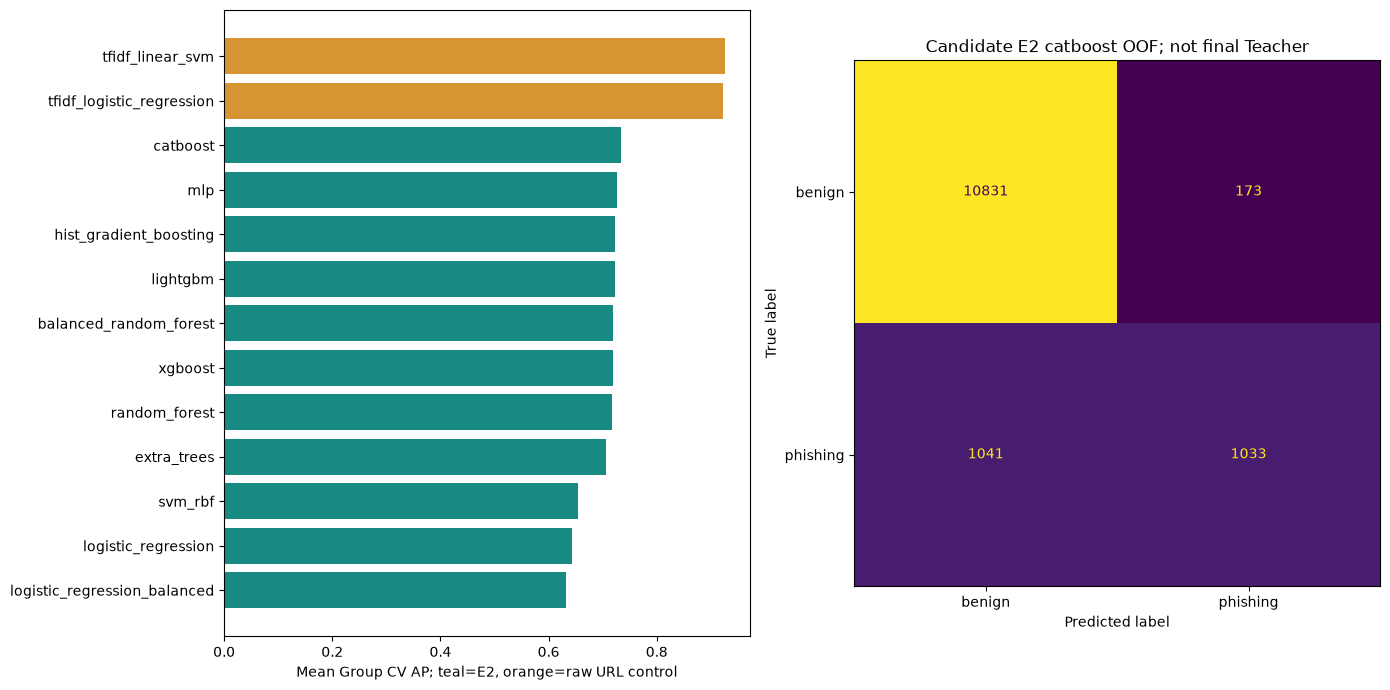

In [9]:
resource_rows = []
for name, fitted in final_models.items():
    stream = BytesIO()
    joblib.dump(fitted, stream)
    durations = []
    sample = model_input(name, train.iloc[:128])
    for repeat in range(35):
        start = perf_counter()
        fitted.predict(sample)
        ranking_scores(fitted, sample)
        if repeat >= 5:
            durations.append((perf_counter() - start) * 1000)
    scope = ("PC predict+score incl. TF-IDF, raw URL input" if name in RAW_MODEL_NAMES
             else "PC predict+score, precomputed E2 X")
    resource_rows.append({"model": name, "pipeline_bytes": stream.tell(), "batch_size": len(sample),
                         "latency_p50_ms": float(np.median(durations)),
                         "latency_p95_ms": float(np.quantile(durations, 0.95)),
                         "scope": scope + ", 1 thread, warmup=5, repeats=30"})
resources = pd.DataFrame(resource_rows)
comparison = comparison.merge(resources, on="model", validate="one_to_one")
display(comparison)
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
ordered = comparison.iloc[::-1]
colors = np.where(ordered["e2_contract_compatible"], "#198a83", "#d69532")
axes[0].barh(ordered["model"], ordered["pr_auc_mean"], color=colors)
axes[0].set_xlabel("Mean Group CV AP; teal=E2, orange=raw URL control")
candidate_rows = oof.loc[oof["model"].eq(candidate_name)]
ConfusionMatrixDisplay.from_predictions(candidate_rows["true_label"], candidate_rows["predicted_label"],
                                       labels=[0, 1], display_labels=["benign", "phishing"], ax=axes[1], colorbar=False)
axes[1].set_title(f"Candidate E2 {candidate_name} OOF; not final Teacher")
fig.tight_layout()
fig.savefig(FIGURES / "teacher_comparison.png", dpi=150)
plt.show()


## 9. Lưu báo cáo và trạng thái chưa chốt

Bảng xếp hạng, OOF, tham số, tài nguyên và lỗi được lưu trong reports/tables/week6. teacher_selection.json ghi selected_candidate=null và teacher_finalized=false. File lock cũng false nên không có Teacher mới được phát hành.

Hai ứng viên dẫn đầu chỉ lưu local trong data/interim để thử reload, không đưa vào Git. Model MLP cũ trong models vẫn là lịch sử từ commit 19ceb7b, không được coi là quyết định mới. Khi nhóm chốt mới xuất Teacher, cập nhật contract/lock và chạy external.


In [10]:
extractor_hashes = {name: hashlib.sha256((ROOT / "src/phishguard_vn" / name).read_bytes().replace(b"\r\n", b"\n")).hexdigest()
                    for name in ["features.py", "url_parser.py", "brand_features.py"]}
score_kind = "decision_function" if candidate_name == "svm_rbf" else "probability"
# Chỉ lưu ứng viên local để kiểm tra reload; chưa thay model Teacher đã bàn giao trước đây.
bundle = {"models": {candidate_name: final_models[candidate_name]}, "selected_model": candidate_name,
          "feature_names": FEATURES, "feature_set": FEATURE_SCHEMA_VERSION,
          "score_kinds": {candidate_name: score_kind}, "protocol": PROTOCOL,
          "decision_rule": "estimator.predict", "brand_reference": reference,
          "extractor_source_sha256": extractor_hashes, "stage": "candidate_not_final_teacher"}
model_path = DATA / "week6_candidate_e2.joblib"
joblib.dump(bundle, model_path)
joblib.dump(final_models[raw_candidate_name], DATA / "week6_candidate_raw_url.joblib")
compression = {"method": "gzip", "mtime": 0}
for name, frame in {"cv_metrics": cv_metrics, "comparison": comparison, "validation": validation_metrics,
                    "parameters": pd.DataFrame(parameter_rows), "errors": error_examples,
                    "resources": resources, "low_fpr_metrics": low_fpr_metrics}.items():
    frame.to_csv(OUT / f"{name}.csv", index=False, encoding="utf-8", lineterminator="\n")
for name, frame in {"oof_predictions": oof, "validation_predictions": validation_predictions,
                    "training_partitions": partitions}.items():
    frame.to_csv(OUT / f"{name}.csv.gz", index=False, compression=compression, lineterminator="\n")
input_paths = [DATA / n for n in ["core_gold_silver.csv", "03_matrix_X_features.csv",
               "03_registrable_domains.csv", "02_group_folds_train.csv",
               "05_matrix_X_brand_trainval.csv", "05_matrix_X_brand_trainval.manifest.json"]]
notebook = nbformat.read(ROOT / "notebooks/06_teacher_v1.ipynb", as_version=4)
training_code = "\n".join(c.source for c in notebook.cells if c.cell_type == "code")
selection = {"protocol": PROTOCOL, "feature_schema_version": FEATURE_SCHEMA_VERSION,
    "created_utc": datetime.now(timezone.utc).isoformat(), "teacher_finalized": False,
    "status": "awaiting_team_decision", "selected_by": "not_finalized", "external_used_for_selection": False,
    "primary_metric": "mean_outer_average_precision", "ranking_rule": "AP desc; F1 desc; FPR asc; model name asc",
    "selected_candidate": None, "leading_e2_candidate": candidate_name, "leading_raw_candidate": raw_candidate_name,
    "e2_candidates": [n for n in models if n not in RAW_MODEL_NAMES],
    "raw_url_controls": sorted(RAW_MODEL_NAMES),
    "train_rows": len(train), "validation_rows": len(validation), "test_evaluated": False,
    "seed": SEED, "outer_folds": 3, "inner_folds": 2, "features": FEATURES,
    "reference": reference.summary(), "extractor_source_lf_sha256": extractor_hashes,
    "notebook_code_sha256": hashlib.sha256(training_code.encode("utf-8")).hexdigest(),
    "runtime_git_revision": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip(),
    "runtime_git_dirty": bool(subprocess.check_output(["git", "status", "--porcelain"], cwd=ROOT, text=True).strip()),
    "versions": {n: version(n) for n in ["scikit-learn", "numpy", "pandas", "joblib", "tldextract", "idna",
                                      "lightgbm", "xgboost", "catboost", "imbalanced-learn"]},
    "input_sha256": {p.relative_to(ROOT).as_posix(): sha256(p) for p in input_paths},
    "parameters": parameter_rows, "candidate_grids": param_grids,
    "prior_results_already_observed": True,
    "low_fpr_analysis": "inner-OOF fitting calibration only; not a deployed operating point",
    "candidate_e2_bundle_local_only": {"path": model_path.relative_to(ROOT).as_posix(), "sha256": sha256(model_path)}}
selection_path = OUT / "teacher_selection.json"
selection_path.write_text(json.dumps(selection, ensure_ascii=False, indent=2) + "\n", encoding="utf-8", newline="\n")
lock = {"teacher_finalized": False, "status": "awaiting_team_decision",
        "selected_by": "not_finalized", "external_used_for_selection": False,
        "reason": "Báo cáo mở rộng để nhóm quyết định model và hợp đồng E2 hay URL thô.",
        "comparison_record": {"path": selection_path.relative_to(ROOT).as_posix(), "sha256": sha256(selection_path)},
        "previous_teacher": {"revision": "19ceb7b", "path": "models/week6_teacher_v1.joblib",
                             "note": "MLP lịch sử, chưa được tái xác nhận sau đợt so sánh mở rộng."}}
(ROOT / "configs/week6_teacher_lock.json").write_text(
    json.dumps(lock, ensure_ascii=False, indent=2) + "\n", encoding="utf-8", newline="\n")
print("Đã lưu báo cáo; chưa xuất/khóa Teacher mới. Candidate chỉ lưu trong data/interim.")


Đã lưu báo cáo; chưa xuất/khóa Teacher mới. Candidate chỉ lưu trong data/interim.


## 10. Minh họa hai ứng viên trên năm URL offline

Thử E2 candidate và raw-URL candidate trên cùng năm chuỗi, chỉ để kiểm tra đường đi predict. Demo không có ground truth mới; không gọi URL đích. File demo ghi rõ candidate_not_final_teacher. Script predict_teacher.py sẽ thông báo chưa chốt thay vì sử dụng model cũ như quyết định mới.


In [11]:
loaded = joblib.load(model_path)
demo_urls = ["https://www.vietcombank.com.vn", "https://vietcombank-login.example.com/xacminh",
             "https://example.com/login?account=123", "https://xn--bcher-kva.de", "https://www.hcmus.edu.vn"]
demo_results = []
for url in demo_urls:
    result = predict_url(url, loaded)
    demo_results.append({"url": url, "stage": "candidate_not_final_teacher", **result})
    raw_model = final_models[raw_candidate_name]
    text = pd.Series([url])
    raw_pred = int(raw_model.predict(text)[0])
    demo_results.append({"url": url, "stage": "candidate_not_final_teacher", "model": raw_candidate_name,
        "label": "phishing" if raw_pred else "benign", "score": float(ranking_scores(raw_model, text)[0]),
        "score_kind": "probability" if hasattr(raw_model, "predict_proba") else "decision_function"})
pd.DataFrame(demo_results).to_csv(OUT / "demo_predictions.csv", index=False, encoding="utf-8", lineterminator="\n")
display(pd.DataFrame(demo_results)[["model", "url", "label", "score", "stage"]])


,model,url,label,score,stage
0,catboost,https://www.vietcombank.com.vn,benign,0.002075,candidate_not_final_teacher
1,tfidf_linear_svm,https://www.vietcombank.com.vn,benign,-0.087164,candidate_not_final_teacher
2,catboost,https://vietcombank-login.example.com/xacminh,phishing,0.996628,candidate_not_final_teacher
3,tfidf_linear_svm,https://vietcombank-login.example.com/xacminh,benign,-0.035598,candidate_not_final_teacher
4,catboost,https://example.com/login?account=123,phishing,0.964243,candidate_not_final_teacher
5,tfidf_linear_svm,https://example.com/login?account=123,benign,-0.712090,candidate_not_final_teacher
6,catboost,https://xn--bcher-kva.de,benign,0.031135,candidate_not_final_teacher
7,tfidf_linear_svm,https://xn--bcher-kva.de,benign,-1.916899,candidate_not_final_teacher
8,catboost,https://www.hcmus.edu.vn,benign,0.007390,candidate_not_final_teacher
9,tfidf_linear_svm,https://www.hcmus.edu.vn,benign,-1.579187,candidate_not_final_teacher


## 11. External đang chờ quyết định Teacher

Không chạy thêm external để chọn ứng viên. Lượt MLP cũ và lượt CatBoost thử trước khi đổi trạng thái đã quan sát external; ghi nhận trung thực trong metadata, không gọi đó là một tập chưa từng xem. 99 mẫu có bằng chứng hostname lịch sử, 68 pending không làm ground truth.

Sau khi nhóm chốt model/contract bằng Core protocol mới khóa artifact và chạy lại phép thử host-only riêng. Các dự đoán external cũ không được trình bày như kết quả của Teacher mới.


In [12]:
# Chưa chốt Teacher thì không gọi external gate hoặc chấm lại external để chọn ứng viên.
external_results = {"status": "NOT_RUN_PENDING_TEACHER", "teacher_finalized": False,
    "external_evaluated_in_current_comparison": False, "official": False,
    "prior_external_results_already_observed": True,
    "historical_observations_not_for_selection": [
        {"model": "mlp", "record": "19ceb7b", "scope": "historical_host_only", "tp": 62, "fn": 30,
         "phishing_support": 92, "benign_support": 7, "fp": 1},
        {"model": "catboost", "record": "initial_expanded_run_before_reopening_decision",
         "scope": "historical_host_only", "tp": 59, "fn": 33, "phishing_support": 92, "benign_support": 7, "fp": 1}],
    "limitations": ["Không dùng các quan sát external đã thấy để chọn/tune.",
                    "99 historical-hostname verified; 68 pending không phải ground truth.",
                    "Chỉ chạy external cho model cuối sau khi nhóm chốt lại Teacher."]}
(OUT / "external_results.json").write_text(
    json.dumps(external_results, ensure_ascii=False, indent=2) + "\n", encoding="utf-8", newline="\n")
for filename in ["external_all_predictions.csv", "external_verified_predictions.csv"]:
    path = OUT / filename
    if path.exists():
        path.unlink()  # Tránh trình bày dự đoán của lần chốt trước như đầu ra Teacher mới.
print("External chưa chạy trong lượt báo cáo này: chờ nhóm chốt Teacher.")


External chưa chạy trong lượt báo cáo này: chờ nhóm chốt Teacher.


## Sau báo cáo này cần làm gì?

Nhóm quyết định E2 hay URL thô dựa trên Core CV, giới hạn biểu diễn, chi phí và yêu cầu web/mobile. Sau đó mới xuất một Teacher, metadata/feature order hoặc vectorizer, kiểm thử load/inference, bàn giao và chạy external. Chưa làm KD, soft targets hoặc export Android. Đọc model ở bước 2; fit/predict ở bước 4; xếp hạng ở bước 5.
